### Загружаем библиотеки и данные

In [214]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.stats.proportion import samplesize_proportions_2indep_onetail

In [86]:
customers = pd.read_csv('../data/olist_customers_dataset.csv')
orders = pd.read_csv('../data/olist_orders_dataset.csv')
order_items = pd.read_csv('../data/olist_order_items_dataset.csv')

In [87]:
orders['order_purchase_timestamp'] = pd.to_datetime(orders['order_purchase_timestamp'])
orders['order_approved_at'] = pd.to_datetime(orders['order_approved_at'])
orders['order_delivered_carrier_date'] = pd.to_datetime(orders['order_delivered_carrier_date'])
orders['order_delivered_customer_date'] = pd.to_datetime(orders['order_delivered_customer_date'])
orders['order_estimated_delivery_date'] = pd.to_datetime(orders['order_estimated_delivery_date'])
order_items['shipping_limit_date'] = pd.to_datetime(order_items['shipping_limit_date'])

### Делаем первичный анализ

In [88]:
class EDA:
    def __init__(self, df: pd.DataFrame):
        self.df = df.copy()


    def info(self):
        result = pd.DataFrame({
            "dtype": self.df.dtypes,
            "null": self.df.isna().sum(),
            "null_%": (self.df.isna().mean() * 100).round(2),
            "unique": self.df.nunique(),
        })
        print(f"Размер: {self.df.shape[0]} rows × {self.df.shape[1]} cols")
        print(f"Память: {self.df.memory_usage(deep=True).sum() / 1024**2:.2f} MB")
        display(result)


    def check_duplicates(self, subset: list[str] | None = None):
        if subset:
            null_mask = self.df[subset].isna().any(axis=1)
        else:
            null_mask = self.df.isna().any(axis=1)
        df = self.df[~null_mask]

        involved = df.duplicated(subset=subset, keep=False)
        extra = df.duplicated(subset=subset)
        groups = df.value_counts(subset=subset) if subset else df.value_counts()
        dup = groups[groups > 1]

        print(f'Всего строк:                         {len(self.df)}')
        print(f'Всего повторяющихся значений:        {involved.sum() - extra.sum()}')
        print(f'Строки с повторяющимися значениями:  {involved.sum()}')
        print(f'Строки, дублирующие другие строки:   {extra.sum()}')
        print(f'Максимум повторов у одного значения: {dup.max() if len(dup) else 0}')
        print(f'Медиана повторов:                    {dup.median() if len(dup) else 0:.0f}')


    def describe_num(self, cols: list[str]):
        df_num = self.df[cols]

        num = df_num.describe().T
        num['skew'] = df_num.skew()
        num['kurt'] = df_num.kurt()

        q1, q3 = num['25%'], num['75%']
        iqr = q3 - q1
        lower = q1 - 1.5 * iqr
        upper = q3 + 1.5 * iqr

        non_null = df_num.notna().sum().replace(0, np.nan)

        outliers_left = df_num.lt(lower, axis=1).sum()
        outliers_right = df_num.gt(upper, axis=1).sum()
        num['outliers_left_%'] = (outliers_left / non_null * 100).round(2)
        num['outliers_right_%'] = (outliers_right / non_null * 100).round(2)

        display(num)

        for col in cols:
            series = df_num[col].dropna()
            _, ax = plt.subplots(1, 2, figsize=(10, 3))
            sns.histplot(series, kde=True, ax=ax[0])
            sns.histplot(series, kde=True, ax=ax[1])
            ax[1].set_title('symlog')
            ax[1].set_xscale('symlog', linthresh=1)
            plt.tight_layout()
            plt.show()


    def describe_cat(self, cols: list[str]):
        for col in cols:
            counts = self.df[col].value_counts(dropna=False).rename('count').to_frame()
            counts['%'] = (counts['count'] / len(self.df) * 100).round(2)

            display(counts)

            sns.barplot(data=counts.reset_index(), x='count', y=col)
            plt.title(col)
            plt.xlabel('count')
            plt.gca().invert_yaxis()
            plt.tight_layout()
            plt.show()


    def describe_dates(self):
        for col in self.df.select_dtypes(include='datetime64').columns.tolist():
            s = self.df[col]
            _, ax = plt.subplots(figsize=(10, 3))
            sns.histplot(s.dropna(), bins=50, ax=ax)
            ax.set_title(col)
            plt.tight_layout()
            plt.show()


    def check_dates_order(self, order: list[str]):
        bad = pd.Series(False, index=self.df.index)
        bad_pair = pd.Series('', index=self.df.index)

        for i, a in enumerate(order):
            for b in order[i + 1:]:
                both = self.df[a].notna() & self.df[b].notna()
                violated = both & (self.df[a] > self.df[b])
                # фиксируем первую найденную пару по каждой строке
                first = violated & (bad_pair == '')
                bad_pair.loc[first] = f'{a} > {b}'
                bad |= violated

        n = int(bad.sum())
        pct = bad.mean() * 100
        print(f'нарушений: {n} ({pct:.2f}%)')

        if n == 0:
            return

        summary = (
            bad_pair[bad]
            .value_counts()
            .rename('rows')
            .to_frame()
            .assign(percent=lambda d: (d['rows'] / n * 100).round(2))
        )
        display(summary)

In [89]:
eda_customers = EDA(customers)

In [90]:
eda_customers.info()

Размер: 99441 rows × 5 cols
Память: 26.59 MB


,dtype,null,null_%,unique
customer_id,str,0,0.0,99441
customer_unique_id,str,0,0.0,96096
customer_zip_code_prefix,int64,0,0.0,14994
customer_city,str,0,0.0,4119
customer_state,str,0,0.0,27


Пустых значений нет; customer_id — позаказный идентификатор пользователя; customer_unique_id — уникальный идентификатор пользователя

In [91]:
eda_customers.check_duplicates(['customer_unique_id'])

Всего строк:                         99441
Всего повторяющихся значений:        2997
Строки с повторяющимися значениями:  6342
Строки, дублирующие другие строки:   3345
Максимум повторов у одного значения: 17
Медиана повторов:                    2


Из 99441 заказа только 3345 от клиентов, которые уже до этого что-то покупали

In [92]:
eda_orders = EDA(orders)

In [93]:
eda_orders.info()

Размер: 99441 rows × 8 cols
Память: 24.66 MB


,dtype,null,null_%,unique
order_id,str,0,0.00,99441
customer_id,str,0,0.00,99441
order_status,str,0,0.00,8
order_purchase_timestamp,datetime64[us],0,0.00,98875
order_approved_at,datetime64[us],160,0.16,90733
order_delivered_carrier_date,datetime64[us],1783,1.79,81018
order_delivered_customer_date,datetime64[us],2965,2.98,95664
order_estimated_delivery_date,datetime64[us],0,0.00,459


,count,%
order_status,,
delivered,96478,97.02
shipped,1107,1.11
canceled,625,0.63
unavailable,609,0.61
invoiced,314,0.32
processing,301,0.30
created,5,0.01
approved,2,0.00


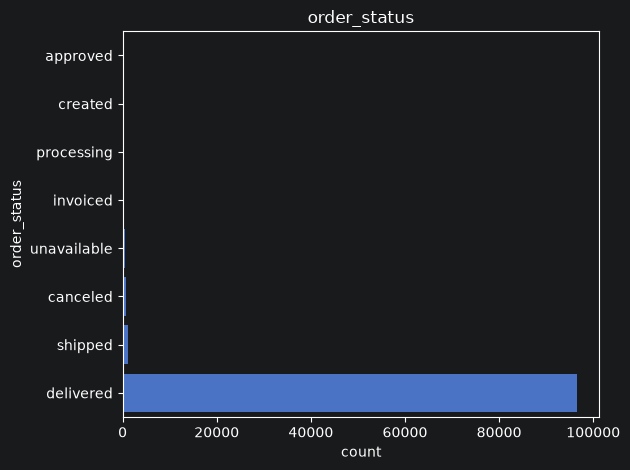

In [94]:
eda_orders.describe_cat(['order_status'])

У небольшого количества заказов нет дат доставки заказа или передачи заказа в логистическую службу, что объясняется отменами заказов, их недоступностью или тем, что их еще не успели доставить

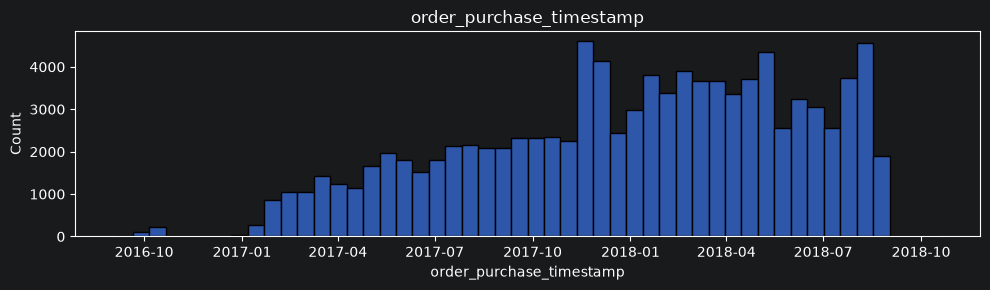

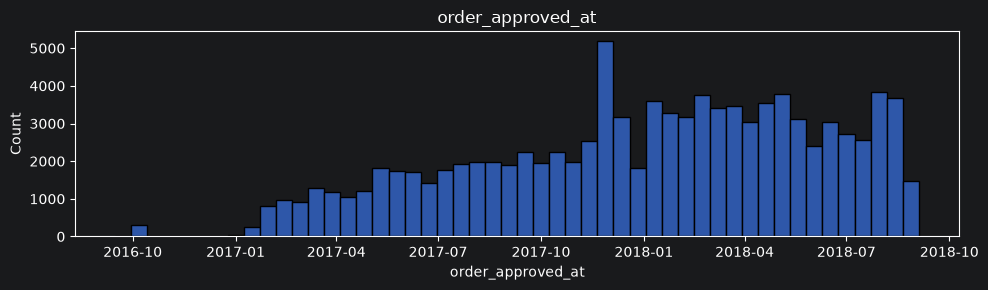

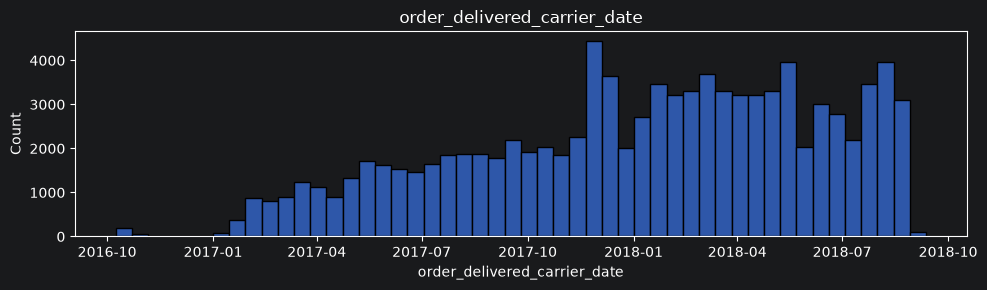

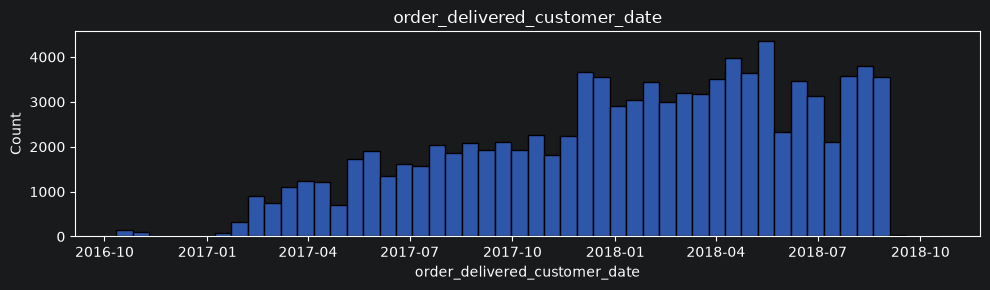

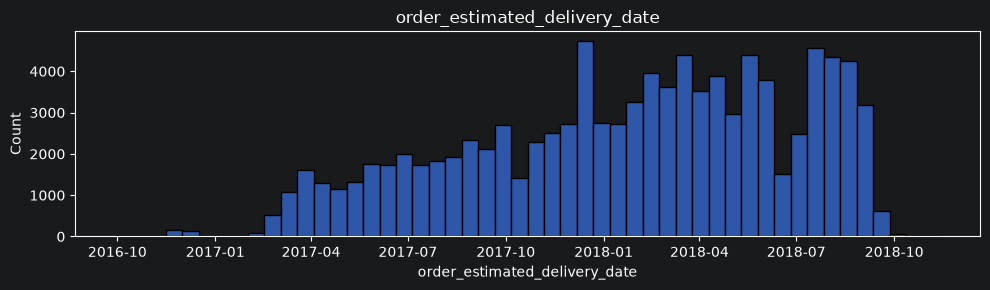

In [95]:
eda_orders.describe_dates()

Видно, что старт заказов пришелся на октябрь 2016, при этом после него до января 2017 заказов либо совсем не было, либо было очень мало

In [96]:
eda_orders.check_dates_order(['order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date', 'order_delivered_customer_date'])

нарушений: 1382 (1.39%)


,rows,percent
order_approved_at > order_delivered_carrier_date,1193,86.32
order_purchase_timestamp > order_delivered_carrier_date,166,12.01
order_delivered_carrier_date > order_delivered_customer_date,23,1.66


Всего 1382 заказа, в которых нарушен логичный порядок дат. И абсолютное большинство это случаи, когда заказ был передан в логистическую службу после его создания, но до подтверждения, что, скорее всего, не является ошибкой в записи. 166 случаев, когда заказ якобы передан в логистическую службу до его создания, что является ошибкой в записи. Еще 23 случая, когда заказ якобы сначала пришел клиенту, а только потом передан в логистическую службу, что так же является ошибкой в записи

In [97]:
eda_orders.check_duplicates(['order_purchase_timestamp'])
eda_orders.check_duplicates(['order_approved_at'])
eda_orders.check_duplicates(['order_delivered_carrier_date'])
eda_orders.check_duplicates(['order_delivered_customer_date'])

Всего строк:                         99441
Всего повторяющихся значений:        556
Строки с повторяющимися значениями:  1122
Строки, дублирующие другие строки:   566
Максимум повторов у одного значения: 3
Медиана повторов:                    2
Всего строк:                         99441
Всего повторяющихся значений:        7045
Строки с повторяющимися значениями:  15593
Строки, дублирующие другие строки:   8548
Максимум повторов у одного значения: 9
Медиана повторов:                    2
Всего строк:                         99441
Всего повторяющихся значений:        10092
Строки с повторяющимися значениями:  26732
Строки, дублирующие другие строки:   16640
Максимум повторов у одного значения: 47
Медиана повторов:                    2
Всего строк:                         99441
Всего повторяющихся значений:        804
Строки с повторяющимися значениями:  1616
Строки, дублирующие другие строки:   812
Максимум повторов у одного значения: 3
Медиана повторов:                    2


In [98]:
print(orders['order_purchase_timestamp'].max() - orders['order_purchase_timestamp'].min())
print(orders['order_approved_at'].max() - orders['order_approved_at'].min())
print(orders['order_delivered_carrier_date'].max() - orders['order_delivered_carrier_date'].min())
print(orders['order_delivered_customer_date'].max() - orders['order_delivered_customer_date'].min())

772 days 20:14:59
718 days 05:23:28
703 days 09:14:27
735 days 23:36:14


За примерно 2 года было: 1) 556 секунд, в которые было одновременно сделано чаще 2, максимум 3 заказа — норма 2) 7045 секунд, в которые было одобрено чаще 2, максимум 9 заказов — скорее всего, одобрение происходило пачками по несколько заказов 3) 10092 секунды, в которые было доставлено в логистическую службу чаще 2, максимум 47 заказов — продавец сдает несколько заказов за раз, и они получают одинаковый datetime 4) 804 секунды, в которые было доставлено клиентам чаще 2, максимум 3 заказа — норма

In [99]:
delivered = orders['order_delivered_customer_date'].notna()
late = delivered & (orders['order_delivered_customer_date'] > orders['order_estimated_delivery_date'])
print(f'Доля опоздавших заказов: {late.sum() / delivered.sum() * 100:.2f}%')

Доля опоздавших заказов: 8.11%


In [100]:
eda_order_items = EDA(order_items)

In [101]:
eda_order_items.info()

Размер: 112650 rows × 7 cols
Память: 29.54 MB


,dtype,null,null_%,unique
order_id,str,0,0.0,98666
order_item_id,int64,0,0.0,21
product_id,str,0,0.0,32951
seller_id,str,0,0.0,3095
shipping_limit_date,datetime64[us],0,0.0,93318
price,float64,0,0.0,5968
freight_value,float64,0,0.0,6999


In [102]:
missing = orders[~orders['order_id'].isin(order_items['order_id'])]

print(missing['order_status'].value_counts())

order_status
unavailable    603
canceled       164
created          5
invoiced         2
shipped          1
Name: count, dtype: int64


775 заказов, которые есть в таблице orders, но нет в таблице order_items. То есть у 775 заказов нет записи о товарах. Это объясняется их статусом: абсолютное большинство таких заказов либо недоступны, либо отменены

,count,mean,std,min,25%,50%,75%,max,skew,kurt,outliers_left_%,outliers_right_%
price,112650.0,120.653739,183.633928,0.85,39.90,74.99,134.90,6735.00,7.923208,120.828298,0.00,7.48
freight_value,112650.0,19.990320,15.806405,0.00,13.08,16.26,21.15,409.68,5.639870,59.788253,0.46,10.31


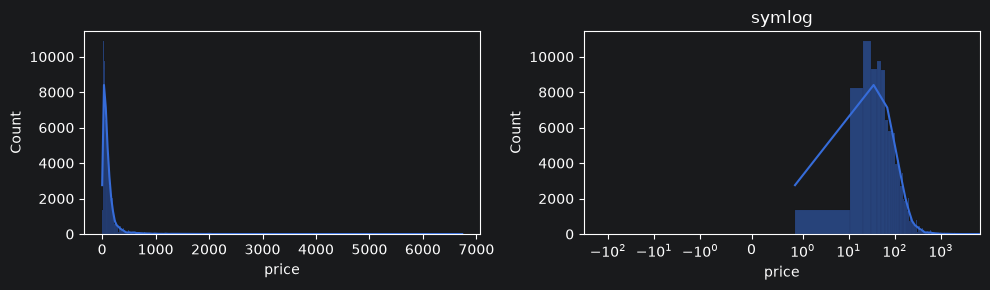

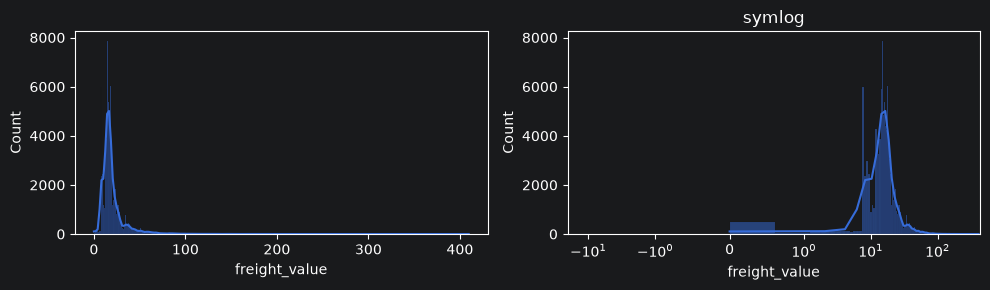

In [103]:
eda_order_items.describe_num(['price', 'freight_value'])

И цена товара, и цена доставки имеет типичное для денег ненормальное распределение, когда большинство значений небольшие, при этом есть значения, которые гораздо больше остальных

### Оцениваем месячный retention в оформлении заказа с помощью когортного анализа

Для расчетов будем брать все заказы независимо от их статуса, потому что если заказ уже был создан, то клиент уже пришел/вернулся в наш маркетплейс и уже был готов отдать деньги за заказ — для нас в данном случае это целевое действие

In [104]:
df_cohort = orders.merge(customers, on='customer_id')[['customer_unique_id', 'order_purchase_timestamp']]

In [105]:
df_cohort['cohort_datetime'] = df_cohort.groupby('customer_unique_id')['order_purchase_timestamp'].transform('min')
df_cohort['cohort_month'] = df_cohort['cohort_datetime'].dt.to_period('M')

In [106]:
df_cohort['period'] = (df_cohort['order_purchase_timestamp'] - df_cohort['cohort_datetime']).dt.days // 30

In [107]:
cohort_analysis = df_cohort.groupby(['cohort_month', 'period']).agg(customers=('customer_unique_id', 'nunique')).reset_index()

In [108]:
cohort_table = cohort_analysis.pivot_table(index='cohort_month', columns='period', values='customers').fillna(0)
cohort_size = cohort_table[0].astype(int)

In [109]:
max_date = df_cohort['order_purchase_timestamp'].max()
cohort_last_start = df_cohort.groupby('cohort_month')['cohort_datetime'].max()
max_period = ((max_date - cohort_last_start).dt.days // 30 - 1).astype(int)

mask = pd.DataFrame(
    cohort_table.columns.values[None, :] > max_period.values[:, None],
    index=cohort_table.index,
    columns=cohort_table.columns,
)

cohort_table = cohort_table.mask(mask)

In [110]:
retention_table = cohort_table.divide(cohort_size, axis=0) * 100

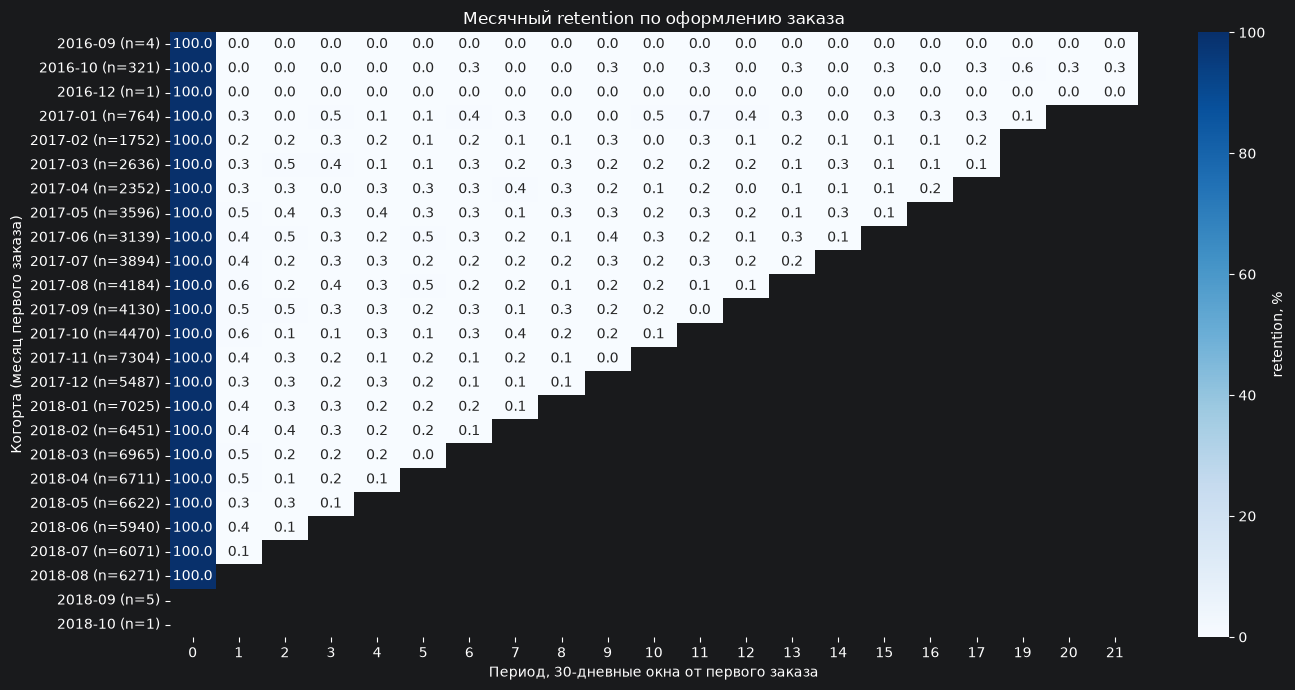

In [111]:
yticklabels = [f'{m} (n={cohort_size.loc[m]})' for m in retention_table.index]

plt.figure(figsize=(14, 7))
sns.heatmap(
    retention_table,
    annot=True,
    fmt='.1f',
    cmap='Blues',
    cbar_kws={'label': 'retention, %'},
    yticklabels=yticklabels,
)
plt.title('Месячный retention по оформлению заказа')
plt.xlabel('Период, 30-дневные окна от первого заказа')
plt.ylabel('Когорта (месяц первого заказа)')
plt.tight_layout()
plt.show()

In [112]:
print(f'медианный retention 1-го месяца:  {retention_table[1].median():.2f}%')

медианный retention 1-го месяца:  0.36%


In [113]:
period3 = retention_table[3]
best_cohort = period3.idxmax()
best_value = period3.max()

print(f'когорта с самым высоким retention на 3-й месяц: {best_cohort}  →  {best_value:.2f}%')

когорта с самым высоким retention на 3-й месяц: 2017-01  →  0.52%


### Оцениваем product/market fit

product/market fit — соответствие продукта рынку, когда продукт удовлетворяет потребности конкретного сегмента аудитории, и, как следствие, пользователи регулярно выбирают его для решения своей задачи

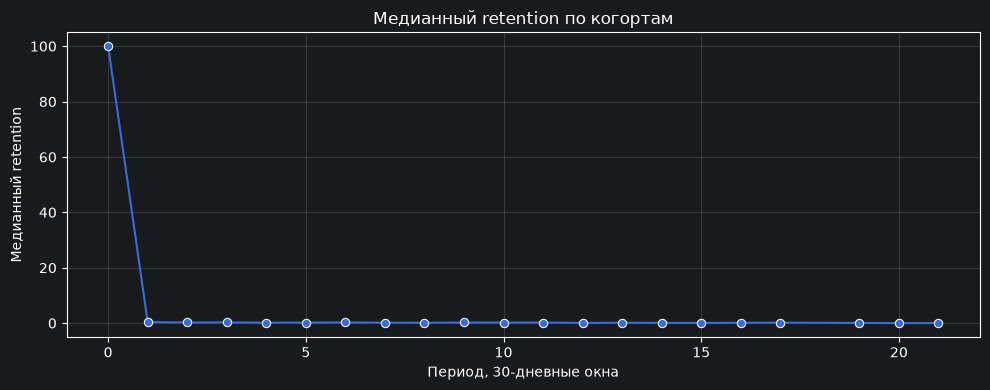

In [114]:
plt.figure(figsize=(10, 4))
sns.lineplot(retention_table.median(), marker='o')
plt.xlabel('Период, 30-дневные окна')
plt.ylabel('Медианный retention')
plt.title('Медианный retention по когортам')
plt.grid(alpha=0.3, which='both')
plt.tight_layout()
plt.show()

Видно, что уже на первом 30-дневном окне после первого заказа регулярность использования резко падает до околонулевых значений. Следовательно, у маркетплейса нет PMF

Возможные причины:
* Частые задержки заказа
* Высокая цена доставки

In [115]:
order_items_price_freight_value = order_items.groupby('order_id').agg({'price': 'sum', 'freight_value': 'sum'}).reset_index()
order_items_price_freight_value['freight_share'] = order_items_price_freight_value['freight_value'] / (order_items_price_freight_value['price'] + order_items_price_freight_value['freight_value'])
(order_items_price_freight_value['freight_share'] * 100).median()

np.float64(18.325606763021543)

В половине заказов клиент платит больше 18% от всей суммы на доставку

In [116]:
df_cohort_filtered = orders.merge(customers, on='customer_id')[['order_id', 'customer_unique_id', 'order_purchase_timestamp', 'order_delivered_customer_date', 'order_estimated_delivery_date']].merge(order_items_price_freight_value, on='order_id')
df_cohort_filtered['delivered_in_time'] = df_cohort_filtered['order_delivered_customer_date'] < df_cohort_filtered['order_estimated_delivery_date']
df_cohort_filtered['cheap_freight'] = df_cohort_filtered['freight_share'] < 0.1
df_cohort_filtered = df_cohort_filtered[['customer_unique_id', 'order_purchase_timestamp', 'delivered_in_time', 'cheap_freight']]

In [117]:
df_cohort_filtered['cohort_datetime'] = df_cohort_filtered.groupby('customer_unique_id')['order_purchase_timestamp'].transform('min')

In [118]:
customers_filtered = df_cohort_filtered.query('delivered_in_time == True and cheap_freight == True and order_purchase_timestamp == cohort_datetime')
df_cohort_filtered = df_cohort_filtered[df_cohort_filtered['customer_unique_id'].isin(customers_filtered['customer_unique_id'])]

In [119]:
df_cohort_filtered['period'] = (df_cohort_filtered['order_purchase_timestamp'] - df_cohort_filtered['cohort_datetime']).dt.days // 30
df_cohort_filtered['cohort_month'] = df_cohort_filtered['cohort_datetime'].dt.to_period('M')

In [120]:
cohort_analysis_filtered = df_cohort_filtered.groupby(['cohort_month', 'period']).agg(customers=('customer_unique_id', 'nunique')).reset_index()
cohort_table_filtered = cohort_analysis_filtered.pivot_table(index='cohort_month', columns='period', values='customers').fillna(0)
cohort_size_filtered = cohort_table_filtered[0].astype(int)
max_date = df_cohort_filtered['order_purchase_timestamp'].max()
cohort_last_start = df_cohort_filtered.groupby('cohort_month')['cohort_datetime'].max()
max_period = ((max_date - cohort_last_start).dt.days // 30 - 1).astype(int)

mask = pd.DataFrame(
    cohort_table_filtered.columns.values[None, :] > max_period.values[:, None],
    index=cohort_table_filtered.index,
    columns=cohort_table_filtered.columns,
)

cohort_table_filtered = cohort_table_filtered.mask(mask)
retention_table_filtered = cohort_table_filtered.divide(cohort_size_filtered, axis=0) * 100

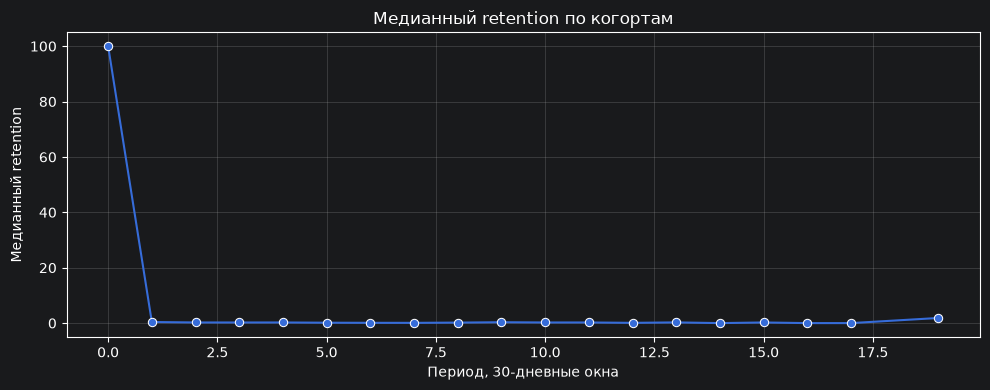

In [121]:
plt.figure(figsize=(10, 4))
sns.lineplot(retention_table_filtered.median(), marker='o')
plt.xlabel('Период, 30-дневные окна')
plt.ylabel('Медианный retention')
plt.title('Медианный retention по когортам')
plt.grid(alpha=0.3, which='both')
plt.tight_layout()
plt.show()

Это retention клиентов, у которых первый заказ был доставлен в срок, и при этом его цена доставки от всей суммы заказа была относительно небольшой. Даже при этом на первом 30-дневном окне после первого заказа регулярность использования резко падает до околонулевых значений. Значит дело вряд ли в цене доставки или задержках

Скорее всего, маркетплейс занимается агрессивным привлечением новых клиентов, а не попытками удержать уже имеющихся. Такая бизнес-модель не может существовать долго, и нужны структурные изменения, чтобы повысить возвращаемость клиентов в продукт

### Определяем основные метрики

Первая метрика должна отражать рост объёма продаж маркетплейса. Для этого лучше всего годится месячный объем продаж: price + freight_value по доставленным заказам за месяц оформления

In [134]:
order_items_price_freight_value['total_price'] = order_items_price_freight_value['price'] + order_items_price_freight_value['freight_value']
order_total_price = order_items_price_freight_value[['order_id', 'total_price']]
order_total_price = order_total_price.merge(orders.query('order_status == "delivered"'), on='order_id')[['total_price', 'order_purchase_timestamp']]
order_total_price['order_purchase_month'] = order_total_price['order_purchase_timestamp'].dt.to_period('M')
GMV = order_total_price.groupby('order_purchase_month')['total_price'].sum()

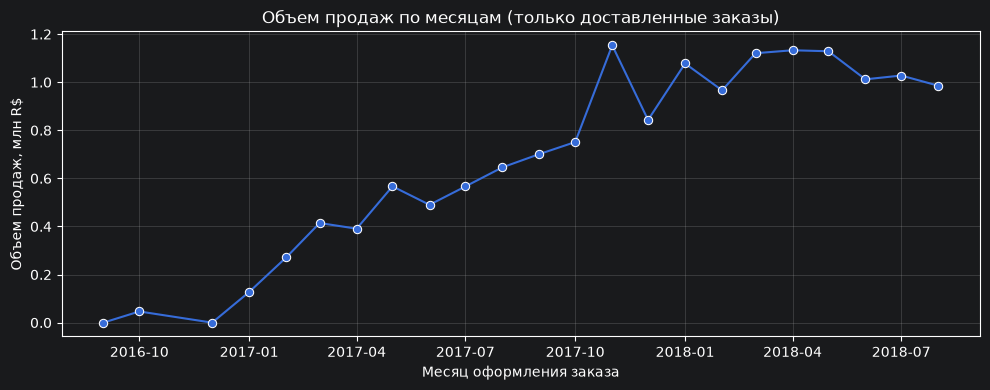

In [135]:
plt.figure(figsize=(10, 4))
sns.lineplot(x=GMV.index.to_timestamp(), y=GMV.values / 1e6, marker='o')
plt.xlabel('Месяц оформления заказа')
plt.ylabel('Объем продаж, млн R$')
plt.title('Объем продаж по месяцам (только доставленные заказы)')
plt.grid(alpha=0.3, which='both')
plt.tight_layout()
plt.show()

Вторая метрика должна показывать объем аудитории, которой продукт доставляет ценность. Для этого лучше всего годится количество уникальных пользователей за месяц с хотя бы одним доставленным заказом (заказ может быть доставлен и в следующие месяцы, считаем по месяцу покупки)

In [124]:
customer_order_purchase_time = orders.query('order_status == "delivered"').merge(customers, on='customer_id')[['customer_unique_id', 'order_purchase_timestamp']]
customer_order_purchase_time['order_purchase_month'] = customer_order_purchase_time['order_purchase_timestamp'].dt.to_period('M')
MAU = customer_order_purchase_time.groupby('order_purchase_month')['customer_unique_id'].nunique()

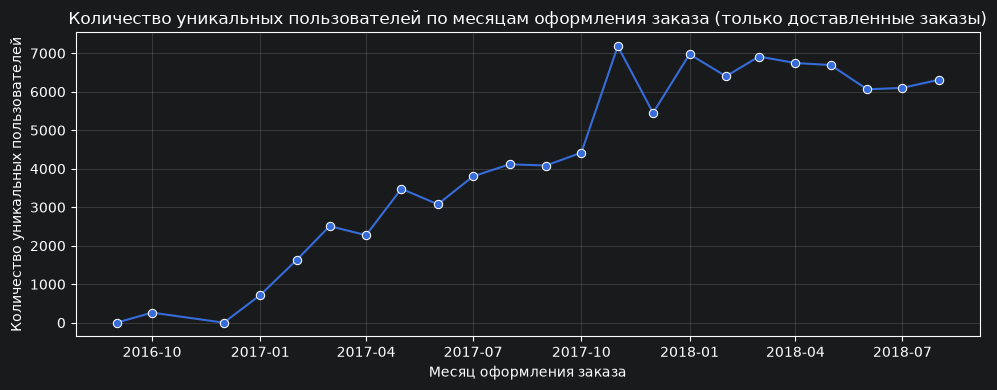

In [125]:
plt.figure(figsize=(10, 4))
sns.lineplot(x=MAU.index.to_timestamp(), y=MAU.values, marker='o')
plt.xlabel('Месяц оформления заказа')
plt.ylabel('Количество уникальных пользователей')
plt.title('Количество уникальных пользователей по месяцам оформления заказа (только доставленные заказы)')
plt.grid(alpha=0.3, which='both')
plt.tight_layout()
plt.show()

Третья метрика должна отражать заинтересованность новых клиентов в продукте. Для этого лучше всего годится конверсия новых пользователей в первый заказ

Четвёртая метрика должна отражать вовлеченность клиента в продолжение использования продукта. Для этого лучше всего годится M1 retention (возврат в следующем месяце)

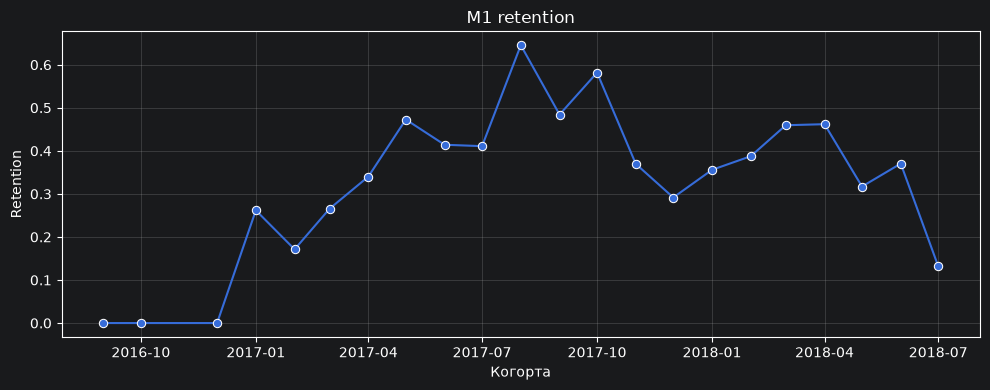

In [147]:
plt.figure(figsize=(10, 4))
sns.lineplot(x=retention_table[1].index.to_timestamp(), y=retention_table[1].values, marker='o')
plt.xlabel('Когорта')
plt.ylabel('Retention')
plt.title('M1 retention')
plt.grid(alpha=0.3, which='both')
plt.tight_layout()
plt.show()

Пятая метрика должна отражать денежное выражение вовлеченности клиента. Для этого лучше всего подходит GMV per buyer (отношение месячного объема продаж к числу активных покупателей в этот месяц)

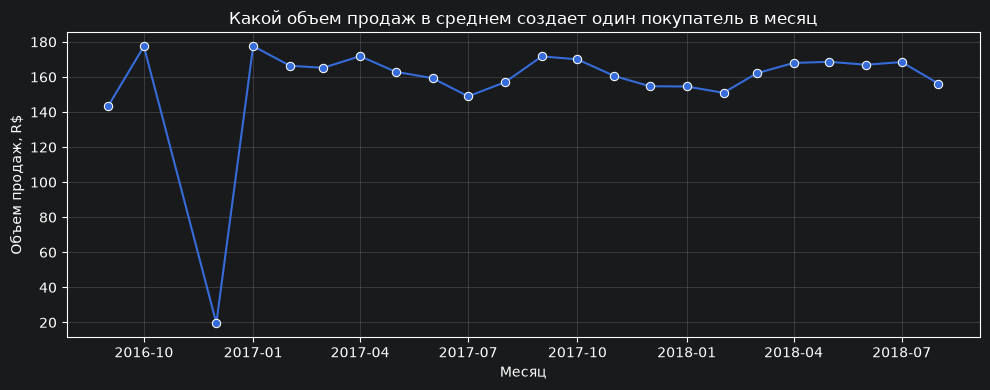

In [148]:
GMV_per_buyer = GMV / MAU
plt.figure(figsize=(10, 4))
sns.lineplot(x=GMV_per_buyer.index.to_timestamp(), y=GMV_per_buyer.values, marker='o')
plt.xlabel('Месяц')
plt.ylabel('Объем продаж, R$')
plt.title('Какой объем продаж в среднем создает один покупатель в месяц')
plt.grid(alpha=0.3, which='both')
plt.tight_layout()
plt.show()

### Выбираем одну из трех гипотез от продакта с помощью фреймворка ICE

* H1: Если исправим баг в системе процессинга заказов, то клиентам не придётся сталкиваться с проблемой отмены заказа, вследствие чего количество доставленных заказов увеличится. Считаем, что мы таким образом избавимся от всех отмен. Confidence: 8. Ease: 6
* H2: Если сократим время до отгрузки заказа, то клиенты перестанут получать свой заказ с запаздыванием, вследствие чего количество заказов увеличится за счёт повторных заказов. Confidence:10. Ease: 4
* H3: Если создадим новый способ оплаты, который будет конвертировать клиентов в повторный заказ, то клиенты не будут испытывать трудности при оформлении заказа, вследствие чего количество заказов увеличится за счёт повторных заказов тех, кто раньше не делал повторный заказ. Confidence: 5. Ease: 9

Для расчета Impact возьмем данные с июня 2017 года. Считаем, что конверсия в повторный заказ равна величине медианного retention 1-го месяца

Для перевода метрики в Impact воспользуемся следующей шкалой:
| Impact | 1 | 2 | 3 | 4 | 5 | 6 | 7 | 8 | 9 | 10 |
|---|---|---|---|---|---|---|---|---|---|---|
| Значение метрики | 0–50 | 51–150 | 151–350 | 351–750 | 751–1550 | 1551–3150 | 3151–6350 | 6351–12750 | 12751–25550 | 25551–51150 |

In [158]:
orders[(orders['order_purchase_timestamp'] >= pd.Timestamp('2017-06-01')) & (orders['order_status'] == 'canceled')].shape[0]

499

Если первая гипотеза верна, то маркетплейс не столкнулся бы с отменой 499 заказов с июня 2017. Исходя из таблицы ее Impact равен 4

In [163]:
orders[(orders['order_purchase_timestamp'] >= pd.Timestamp('2017-06-01')) & (orders['order_delivered_customer_date'] > orders['order_estimated_delivery_date'])].shape[0] * 0.0036

26.2656

Если вторая гипотеза верна, то маркетплейс получил бы 26 повторных заказов с июня 2017. Исходя из таблицы ее Impact равен 1

In [167]:
EDA(orders[orders['order_purchase_timestamp'] >= pd.Timestamp('2017-06-01')].merge(customers, on='customer_id')).check_duplicates(['customer_unique_id'])

Всего строк:                         87746
Всего повторяющихся значений:        2460
Строки с повторяющимися значениями:  5187
Строки, дублирующие другие строки:   2727
Максимум повторов у одного значения: 16
Медиана повторов:                    2


In [169]:
print((87746-5187)*0.0036)

297.2124


Если третья гипотеза верна, то маркетплейс получил бы 297 повторных заказов с июня 2017. Исходя из таблицы ее Impact равен 3

In [170]:
print(8*6*4)
print(10*4*1)
print(5*9*3)

192
40
135


По итоговому баллу первая гипотеза является самой приоритетной

### Выбираем метрики для проверки гипотезы

Гипотеза предполагает, что после исправления бага, клиенты перестанут сталкиваться с проблемой отмены заказа, вследствие чего количество доставленных заказов увеличится. Поэтому в качестве целевой метрики нужно использовать долю доставленных заказов. В качестве второй целевой метрики можно использовать долю отмененных заказов, на ней легче заметить изменения

In [199]:
mask = orders['order_approved_at'].isna()

canceled = orders['order_status'] == 'canceled'
print(f'доля отменённых с null-одобрением: {mask[canceled].mean()}')
print(f'доля доставленных с null-одобрением: {mask[orders['order_status'] == 'delivered'].mean()}')

print('\nдоля null-одобрений по статусам:')
print(orders.loc[mask, 'order_status'].value_counts(normalize=True))

доля отменённых с null-одобрением: 0.2256
доля доставленных с null-одобрением: 0.00014511080246273761

доля null-одобрений по статусам:
order_status
canceled     0.88125
delivered    0.08750
created      0.03125
Name: proportion, dtype: float64


Видно, что 23% отмененных заказов имеют order_approved_at равным null. При этом если мы видим у заказа order_approved_at равным null, то с огромной вероятностью это отмененный заказ. Из этого можно сделать прокси метрику: долю заказов с order_approved_at равным null. Она может сигнализировать об изменениях раньше, чем целевые

При этом, с увеличением доли доставленных заказов, доля задержавшихся заказов не должна расти. Это будет guardrail метрикой

### Оцениваем размер групп для A/B теста

In [216]:
samplesize_proportions_2indep_onetail(
    diff=-0.0063,
    prop2=0.0063,
    power=0.80,
    ratio=1,
    alpha=0.05,
    alternative='two-sided'
)

np.float64(1240.7498968232076)

In [212]:
orders['order_purchase_timestamp'].dt.to_period('D').value_counts().median()

np.float64(148.0)

In [218]:
print(1241*2/148)

16.77027027027027


При ожидаемом эффекте равным полному устранению отмен, при пороге значимости равным 0.05, при мощности равной 0.8, на каждую группу нужно 1241 заказ. При медианном количестве заказов в день равным 148, понадобится 17 дней эксперимента